# T15: Promise-keeping, not speed

Team: Bi Ronglin, Chen Siying, Shi Jiayan. Dataset 5: Service requests. Theme: The Liveable City.

Residents do not reward a fast fix; they punish a missed promise. Falling short of the promised target moves the mean rating by 2.86 stars, while department, priority and reporting channel move it by 0.37, 0.02 and 0.11.

Contents: setup, Milestone 1 card, data loading and cleaning, exploration, four sub-questions with figures, interactive index, BI tables, sources, findings, recommendation, limitations.

## Setup

Libraries, palette, paths and drawing helpers. The setup cell finds `data/service_requests.csv` from the working directory, so the folder can be moved without editing paths.

In [1]:
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image

# Walk up from cwd so the folder stays portable.
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "service_requests.csv").exists():
            return p
    return start

ROOT = find_root()
DATA_DIR = ROOT / "data"
FIG_DIR  = ROOT / "figures" / "static"
INT_DIR  = ROOT / "figures" / "interactive"
BI_DIR   = ROOT / "bi_export"
for folder in (FIG_DIR, INT_DIR, BI_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Okabe-Ito palette (colour-blind safe).
OK = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73",
      "yellow": "#F0E442", "blue": "#0072B2", "vermillion": "#D55E00",
      "purple": "#CC79A7", "grey": "#7F7F7F"}
KEPT, MISS, NEUTRAL, ACCENT = OK["blue"], OK["vermillion"], OK["grey"], OK["orange"]
INK, MUTED = "#22303c", "#5a5346"

DEPT_COLOR = {
    "Roads & Lighting":     OK["blue"],
    "Waste & Cleanliness":  OK["green"],
    "Water":                OK["sky"],
    "Parks":                OK["orange"],
    "Environment & Noise":  OK["purple"],
    "Citizen Services":     OK["vermillion"],
}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9.5,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 8,
    "axes.labelsize": 10, "axes.labelcolor": "#3d3d3d",
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E7E3DB", "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
})

SRC = ("Source: simulated Meridia service-request data, 2024-2025 "
       "(n = {n:,} closed requests). Meridia is a fictional city; "
       "values are illustrative, not real.")

def fig_header(fig, title, sub, top=0.84):
    fig.subplots_adjust(top=top)
    fig.text(0.004, 0.995, title, fontsize=14.5, fontweight="bold",
             ha="left", va="top", color="#1b1b1b")
    fig.text(0.004, 0.933, textwrap.fill(sub, 108), fontsize=9.6, ha="left", va="top",
             color=MUTED, linespacing=1.35)

def src_note(fig, n, dy=-0.02):
    fig.text(0.004, dy, SRC.format(n=n), ha="left", va="top",
             fontsize=7.6, color="#8a8a8a")

def save_fig(fig, name, n):
    """Save the PNG and check the file exists."""
    out = FIG_DIR / name
    fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    img = plt.imread(out)
    print(f"saved {name}  {img.shape[1]}x{img.shape[0]} px  {out.stat().st_size/1024:.0f} kB")
    display(Image(filename=str(out), width=1180))

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 64)

print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)


pandas 3.0.6 | matplotlib 3.11.2


## 0. Milestone 1 card

Question: does speed or keeping the promised target time drive citizen ratings? SQ1 delay against target, SQ2 departments, SQ3 priority, SQ4 reporting channel.

Audience: Director of Citizen Services and city council, for the 2026 budget and 2030 plan. The decision is capacity in services that miss their target, and on-time rate as the department KPI. Theme: predictable daily life as evidence for a better Meridia.

Data: 31,801 requests x 13 columns, 2024-01-01 to 2025-12-31, 12 districts (`created_at`, `closed_at`, `target_hours`, `citizen_rating`, `department`, `priority`, `channel`, `category`, `district_id`, coordinates). Cleaning: 0 duplicate ids, 0 broken coordinates, 636 category labels mapped, 236 open and 63 negative-duration requests excluded, 65% of ratings left missing (tested in 2.1).

Figures: delay bands and absolute vs relative time (SQ1), department and service comparisons (SQ2), priority (SQ3), channel (SQ4), monthly trend and district map (context). Dashboard tables in `bi_export/`, built in Power BI Desktop (section 6).

Roles: Bi Ronglin - outline, import and cleaning, charts, dashboard; Chen Siying - notebook formatting, cleaning, chart selection, dashboard review; Shi Jiayan - run tests, output consistency, requirement checks.

Risks: rating missingness (tested in 2.1, every rating figure states its n) and `target_hours` depending on category x priority, so promise and normal wait cannot be fully separated (section 10).

## 1. Data loading

In [6]:
req = pd.read_csv(DATA_DIR / "service_requests.csv",
                  parse_dates=["created_at", "closed_at"])

districts = pd.read_csv(DATA_DIR / "districts.csv")
print(f"service_requests.csv : {req.shape[0]:,} rows x {req.shape[1]} columns")
print(f"districts.csv        : {districts.shape[0]:,} rows x {districts.shape[1]} columns")
print(f"period               : {req.created_at.min():%Y-%m-%d} to {req.created_at.max():%Y-%m-%d}")

display(req.head(3))
display(req.dtypes.astype(str).to_frame("dtype"))


service_requests.csv : 31,801 rows x 13 columns
districts.csv        : 12 rows x 8 columns
period               : 2024-01-01 to 2025-12-31


,request_id,created_at,closed_at,status,district_id,latitude,longitude,channel,category,priority,department,target_hours,citizen_rating
0,REQ000001,2024-01-01 23:26:00,2024-01-05 11:10:00,closed,D05,31.065,-39.988,mobile_app,illegal_dumping,medium,Waste & Cleanliness,96,NaN
1,REQ000002,2024-01-01 23:29:00,2024-01-03 06:15:00,closed,D06,31.054,-39.950,mobile_app,streetlight,medium,Roads & Lighting,120,NaN
2,REQ000003,2024-01-01 08:45:00,2024-01-02 23:03:00,closed,D09,31.039,-39.989,mobile_app,road_damage,high,Roads & Lighting,24,NaN


,dtype
request_id,str
created_at,datetime64[us]
closed_at,datetime64[us]
status,str
district_id,str
latitude,float64
longitude,float64
channel,str
category,str
priority,str


Two tables: 31,801 service requests and 12 districts. Timestamps are parsed on load because every duration depends on them. The cell below prints shapes, period and column types.

## 2. Data hygiene

Six checks, each logged with what was found, the decision and the number of rows affected.

In [ ]:
log = []
before = len(req)
n_dup   = int(req["request_id"].duplicated().sum())
n_coord = int(req[["latitude", "longitude"]].isna().any(axis=1).sum())
n_stat  = int(((req["status"] == "open") & req["closed_at"].notna()).sum()
              + ((req["status"] == "closed") & req["closed_at"].isna()).sum())
log.append(["0", f"Integrity checks: {n_dup} duplicate ids, {n_coord} missing coordinates, "
            f"{n_stat} status/closed_at conflicts",
            "Nothing to fix", "Cheap checks first: a problem here would invalidate later steps",
            f"{before:,} -> {before:,}"])
label_fix = {"Waste Collection": "waste_collection",
             "Streetlight": "streetlight",
             "street light": "streetlight"}
n_label = int(req["category"].isin(label_fix).sum())
req["category"] = req["category"].replace(label_fix)
log.append(["1", f"Inconsistent category labels ({n_label} rows)",
            "Map to one lower-case code per service",
            "The same service must be counted once, not three times",
            f"{before:,} -> {len(req):,}"])

req["hours"] = (req["closed_at"] - req["created_at"]).dt.total_seconds() / 3600
log.append(["2", "The file has no duration column",
            "hours = (closed_at - created_at) / 3600",
            "Duration is the core measure of SQ1",
            f"{len(req):,} -> {len(req):,}"])

n_open = int((req["status"] == "open").sum())
log.append(["3", f"{n_open} requests still open on 31 Dec 2025",
            "Exclude them from the duration analysis",
            "No closing time means no duration; including them would bias every average",
            f"{len(req):,} -> {len(req) - n_open:,}"])

neg = (req["status"] == "closed") & (req["hours"] < 0)
n_neg = int(neg.sum())
log.append(["4", f"{n_neg} rows closed before they were created",
            "Exclude them",
            "A negative duration is impossible; the record cannot be repaired",
            f"{len(req) - n_open:,} -> {len(req) - n_open - n_neg:,}"])
C = req[(req["status"] == "closed") & (req["hours"] >= 0)].copy()
C["ratio"] = C["hours"] / C["target_hours"]
C["missed"] = C["ratio"] > 1

rated = C[C["citizen_rating"].notna()].copy()
log.append(["5", f"{len(C) - len(rated):,} closed requests have no rating "
            f"({1 - len(rated)/len(C):.1%})",
            "Do not impute; analyse the rated sample and test missingness",
            "The rating comes after closure; empty means the resident did not answer",
            f"{len(C):,} -> {len(rated):,} rated"])

log_df = pd.DataFrame(log, columns=["Step", "Issue found", "Decision", "Why", "Rows before -> after"])
display(log_df)
print(f"analysis sample C : {len(C):,} closed requests")
print(f"rated sample      : {len(rated):,} ({len(rated)/len(C):.1%} of closed requests)")


,Step,Issue found,Decision,Why,Rows before -> after
0,0,"Integrity checks: 0 duplicate ids, 0 missing coordinates, 0 ...",Nothing to fix,Cheap checks first: a problem here would invalidate later steps,"31,801 -> 31,801"
1,1,Inconsistent category labels (636 rows),Map to one lower-case code per service,"The same service must be counted once, not three times","31,801 -> 31,801"
2,2,The file has no duration column,hours = (closed_at - created_at) / 3600,Duration is the core measure of SQ1,"31,801 -> 31,801"
3,3,236 requests still open on 31 Dec 2025,Exclude them from the duration analysis,No closing time means no duration; including them would bias...,"31,801 -> 31,565"
4,4,63 rows closed before they were created,Exclude them,A negative duration is impossible; the record cannot be repa...,"31,565 -> 31,502"
5,5,"20,530 closed requests have no rating (65.2%)",Do not impute; analyse the rated sample and test missingness,The rating comes after closure; empty means the resident did...,"31,502 -> 10,972 rated"


analysis sample C : 31,502 closed requests
rated sample      : 10,972 (34.8% of closed requests)


Duplicate ids, missing coordinates and status contradictions are all zero. 636 rows get a standard category label. Durations are built as closing minus creation in hours; 236 open and 63 negative-duration requests are dropped (under 1%). The analysis sample C has 31,502 rows, with `ratio` = actual / target and `missed` = 1 when the target was broken. 65% of ratings are missing; they are not imputed, and the 10,972 rated requests are kept as a separate sample.

### 2.1 Is the missing rating random?

65% of closed requests have no rating. Before using the rated sample, check whether being rated depends on how the request was handled.

In [7]:
by_channel  = C.groupby("channel")["citizen_rating"].apply(lambda s: s.notna().mean())
by_district = C.groupby("district_id")["citizen_rating"].apply(lambda s: s.notna().mean())
by_outcome  = C.groupby("missed")["citizen_rating"].apply(lambda s: s.notna().mean())

print(f"rated share by channel  : {by_channel.min():.1%} - {by_channel.max():.1%}")
print(f"rated share by district : {by_district.min():.1%} - {by_district.max():.1%}")
print(f"rated share by outcome  : {by_outcome.min():.1%} - {by_outcome.max():.1%}")

display(pd.DataFrame({"rated share": by_channel, "closed requests": C.groupby("channel").size()}))


rated share by channel  : 34.7% - 35.2%
rated share by district : 33.4% - 36.4%
rated share by outcome  : 34.6% - 35.0%


,rated share,closed requests
channel,,
in_person,0.351578,2028
mobile_app,0.347896,14832
phone,0.348859,9554
web,0.347091,5088


Rated share by channel 34.7-35.2%, by district 33.4-36.4%, by outcome 34.6-35.0%. The flat profile gives no sign that rating depends on the outcome, so the rated sample is treated as representative.

## 3. Exploration

Three overall facts: how long requests take, how residents rate them, and how much of the two years is late.

closed requests      : 31,502
on-time rate         : 61.9%
median time to close : 72.3 h
90th percentile      : 301.4 h
mean rating          : 4.20 (n = 10,972)
saved S0_exploration.png  1449x639 px  84 kB


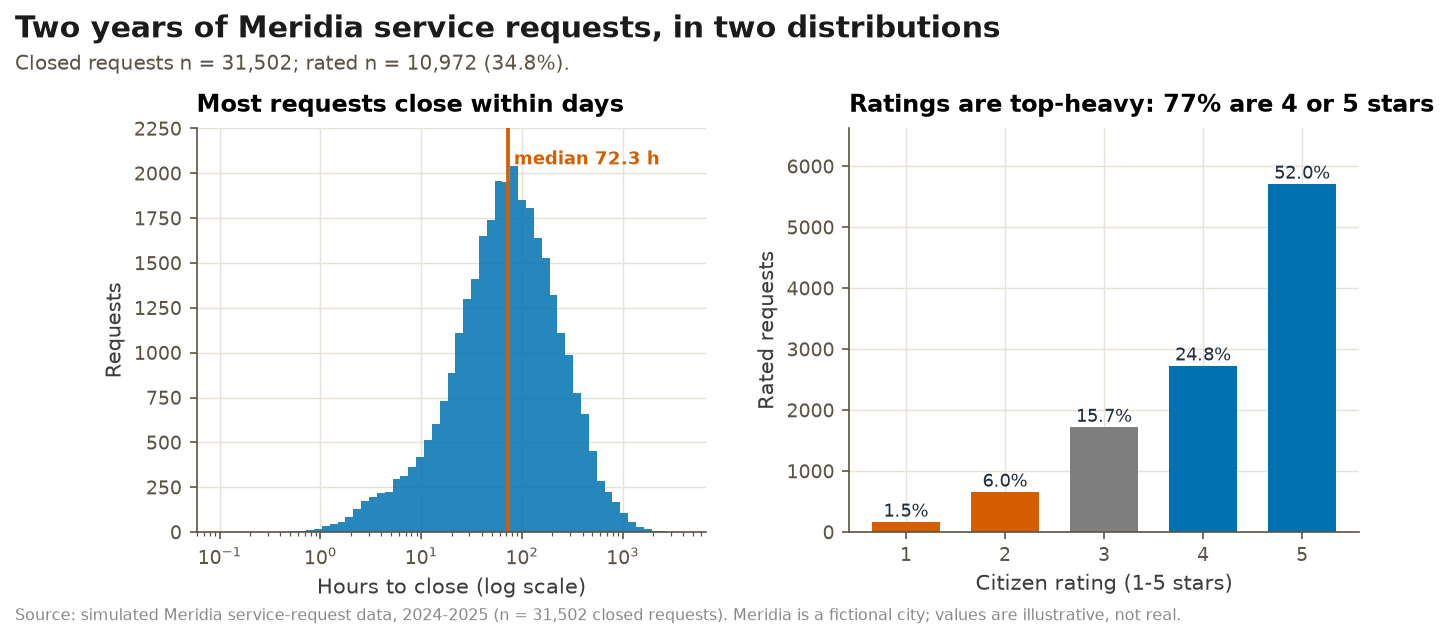

In [8]:
print(f"closed requests      : {len(C):,}")
print(f"on-time rate         : {(~C.missed).mean():.1%}")
print(f"median time to close : {C.hours.median():.1f} h")
print(f"90th percentile      : {C.hours.quantile(0.90):.1f} h")
print(f"mean rating          : {rated.citizen_rating.mean():.2f} (n = {len(rated):,})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.0, 3.9), gridspec_kw={"wspace": 0.28})

# Log x axis: durations are right-skewed.
ax1.hist(C.hours.clip(lower=0.1), bins=np.logspace(-1, 3.6, 60), color=KEPT, alpha=0.85)
ax1.set_xscale("log")
ax1.set_ylim(0, 2250)
ax1.axvline(C.hours.median(), color=MISS, lw=1.8)
ax1.text(C.hours.median() * 1.15, 2050, f"median {C.hours.median():.1f} h",
         fontsize=8.8, color=MISS, fontweight="bold")
ax1.set_xlabel("Hours to close (log scale)")
ax1.set_ylabel("Requests")
ax1.set_title("Most requests close within days")
counts = rated.citizen_rating.value_counts().sort_index()
ax2.bar(counts.index, counts.values, color=[MISS, MISS, NEUTRAL, KEPT, KEPT], width=0.68)
for x, v in counts.items():
    ax2.text(x, v + 90, f"{v/counts.sum():.1%}", ha="center", fontsize=8.6, color=INK)
ax2.set_xlabel("Citizen rating (1-5 stars)")
ax2.set_ylabel("Rated requests")
ax2.set_title("Ratings are top-heavy: 77% are 4 or 5 stars")
ax2.set_ylim(0, counts.max() * 1.16)

fig_header(fig, "Two years of Meridia service requests, in two distributions",
           f"Closed requests n = {len(C):,}; rated n = {len(rated):,} ({len(rated)/len(C):.1%}).",
           top=0.80)
src_note(fig, len(C))
save_fig(fig, "S0_exploration.png", len(C))


31,502 closed requests, 61.9% on time. Median duration 72.3 h, 90th percentile 301 h, mean 128 h, so durations are right-skewed and the axis is log. Mean rating 4.20 on 10,972 rated requests; 77% are 4-5 stars and 7.5% are 1-2 stars. Later figures track both the mean and the low-star share.

## 4. Figures by sub-question

| File | Question |
|---|---|
| `S0_exploration.png` | context |
| `S1_delay_ratio_rating.png`, `S2_absolute_vs_relative.png`, `I1_sq1_switchable_scatter.html` | SQ1 |
| `S3_department_rating.png`, `S4_category_miss_rate.png`, `I2_sq2_service_bubble.html` | SQ2 |
| `S5_priority_speed_vs_rating.png`, `I3_sq3_priority_cloud.html` | SQ3 |
| `S6_channel_dumbbell.png`, `I4_sq4_channel_bars.html` | SQ4 |
| `S7_monthly_volume_and_miss.png`, `S8_request_rate_map.png`, `I5_request_rate_map.html` | context |

Static figures are 150-dpi PNGs in `figures/static/`; the HTML pages in `figures/interactive/` embed plotly.js and open offline.

### 4.1 SQ1: does delay against the promised target drive the rating?

Band rated requests by `ratio` = actual / target, then compare mean rating and the share of 1-2 star ratings across bands.

,n,mean,low
ratio,,,
< 0.5x,2968,4.94,0.03
0.5-1x,3850,4.53,0.55
1-1.5x,1952,3.86,4.20
1.5-2x,956,3.38,12.66
2-3x,818,2.80,35.57
> 3x,428,2.08,71.03


saved S1_delay_ratio_rating.png  1458x730 px  85 kB


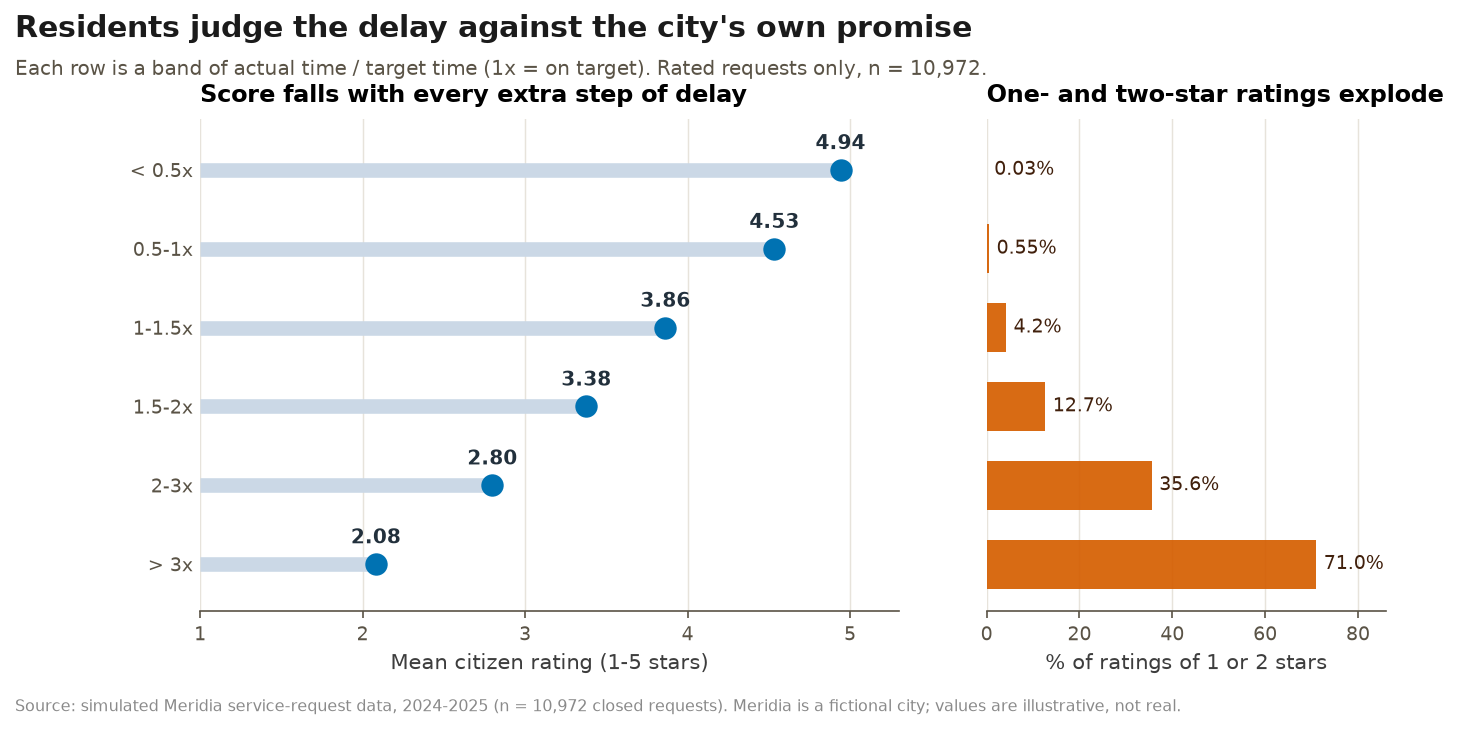

In [6]:
bands = [0, 0.5, 1.0, 1.5, 2.0, 3.0, np.inf]
labels = ["< 0.5x", "0.5-1x", "1-1.5x", "1.5-2x", "2-3x", "> 3x"]
band = pd.cut(rated["ratio"], bins=bands, labels=labels, right=False)

t = rated.groupby(band, observed=False).agg(
    n=("request_id", "size"),
    mean=("citizen_rating", "mean"),
    low=("citizen_rating", lambda s: s.le(2).mean()))
display(t.assign(mean=t["mean"].round(2), low=(t["low"] * 100).round(2)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 4.5),
                               gridspec_kw={"wspace": 0.16, "width_ratios": [1.75, 1]})
y = np.arange(len(t))[::-1]

ax1.hlines(y, 1.0, t["mean"], color="#CBD8E6", lw=7, zorder=1)
ax1.scatter(t["mean"], y, s=95, color=KEPT, zorder=3)
for yy, v in zip(y, t["mean"]):
    ax1.annotate(f"{v:.2f}", (v, yy), textcoords="offset points", xytext=(0, 10),
                 ha="center", fontsize=9.6, fontweight="bold", color=INK)
ax1.set_yticks(y, t.index)
ax1.set_xlim(1.0, 5.3); ax1.set_xticks([1, 2, 3, 4, 5])
ax1.set_ylim(-0.6, len(t) - 0.35)
ax1.set_xlabel("Mean citizen rating (1-5 stars)")
ax1.grid(axis="y", visible=False)
ax1.set_title("Score falls with every extra step of delay")

ax2.barh(y, t["low"] * 100, color=MISS, alpha=0.92, height=0.62)
for yy, v in zip(y, t["low"] * 100):
    ax2.text(v + 1.6, yy, f"{v:.2f}%" if v < 1 else f"{v:.1f}%", va="center",
             fontsize=9, color="#41200c")
ax2.set_yticks(y, [""] * len(t))
ax2.set_xlim(0, 86); ax2.set_ylim(-0.6, len(t) - 0.35)
ax2.set_xlabel("% of ratings of 1 or 2 stars")
ax2.grid(axis="y", visible=False)
ax2.set_title("One- and two-star ratings explode")

for ax in (ax1, ax2):
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig_header(fig, "Residents judge the delay against the city's own promise",
           "Each row is a band of actual time / target time (1x = on target). Rated requests only, n = 10,972.")
src_note(fig, len(rated))
save_fig(fig, "S1_delay_ratio_rating.png", len(rated))


In [7]:
onoff = (rated.groupby("missed")
              .agg(n=("request_id", "size"),
                   mean=("citizen_rating", "mean"),
                   low=("citizen_rating", lambda s: s.le(2).mean())))
onoff.index = ["met the target", "missed the target"]
onoff["share_1_2_star"] = (onoff.pop("low") * 100).round(2)
onoff["mean"] = onoff["mean"].round(2)
display(onoff)

print(f"on-time mean {onoff.loc['met the target', 'mean']:.2f} vs "
      f"late mean {onoff.loc['missed the target', 'mean']:.2f}; "
      f"1-2 star share {onoff.loc['met the target', 'share_1_2_star']:.2f}% vs "
      f"{onoff.loc['missed the target', 'share_1_2_star']:.2f}%")


,n,mean,share_1_2_star
met the target,6820,4.71,0.32
missed the target,4152,3.36,19.22


on-time mean 4.71 vs late mean 3.36; 1-2 star share 0.32% vs 19.22%


Mean rating falls from 4.94 stars (under half the promised time) to 2.08 (over three times the target), a 2.86-star span; the 1-2 star share rises from 0.03% to 71.0%. On-time vs late gives 4.71 vs 3.36 stars.

The bands (0.5 / 1 / 1.5 / 2 / 3 times the target) are a choice; other cuts move the numbers slightly but not the direction. This is an association, not a causal effect.

mean rating by absolute hours, keeping ONLY requests that met their target:
hours
<=12      4.79
12-24     4.79
24-48     4.75
48-96     4.70
96-192    4.61
>192      4.46
saved S2_absolute_vs_relative.png  1358x715 px  112 kB


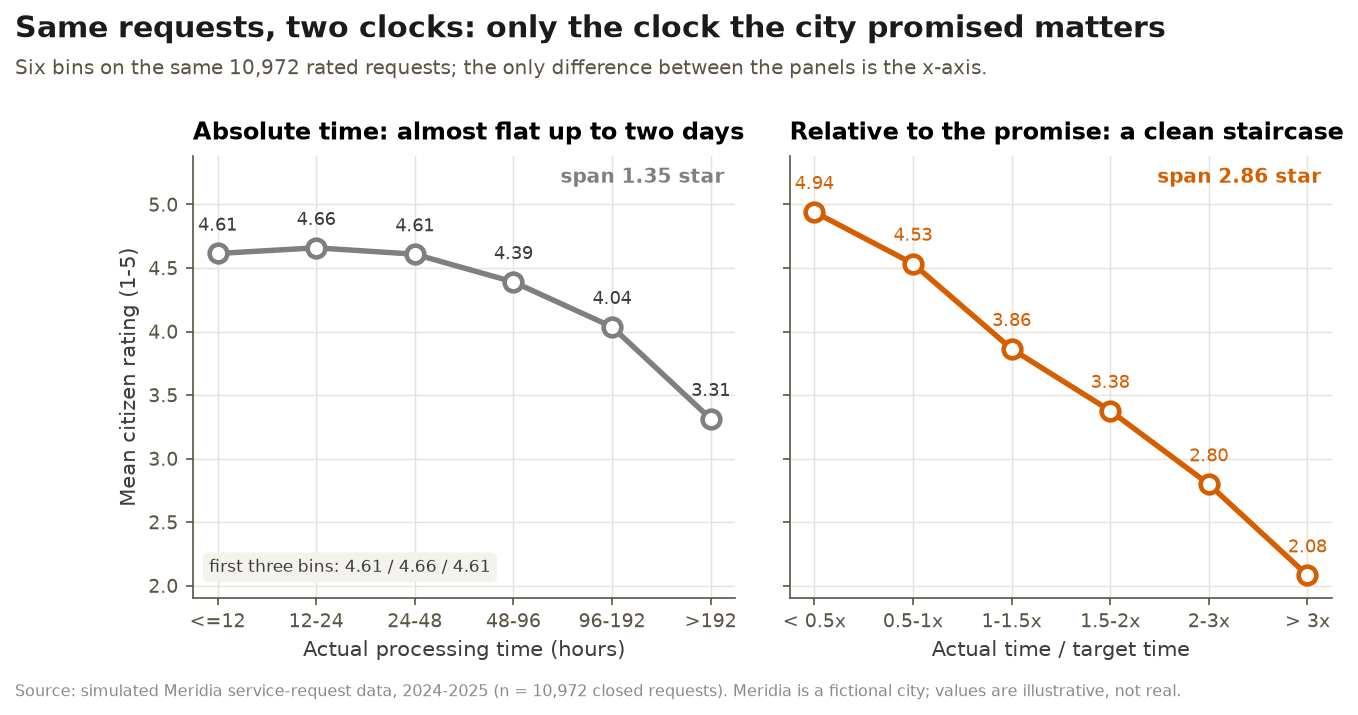

In [8]:
h_bins = [0, 12, 24, 48, 96, 192, np.inf]
h_labels = ["<=12", "12-24", "24-48", "48-96", "96-192", ">192"]
hb = pd.cut(rated["hours"], bins=h_bins, labels=h_labels, right=False)
ht = rated.groupby(hb, observed=False).agg(n=("request_id", "size"),
                                           mean=("citizen_rating", "mean"))

kept = rated[~rated["missed"]]
kcut = pd.cut(kept["hours"], bins=h_bins, labels=h_labels, right=False)
kt = kept.groupby(kcut, observed=False)["citizen_rating"].mean()
print("mean rating by absolute hours, keeping ONLY requests that met their target:")
print(kt.round(2).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.8, 4.4), sharey=True,
                               gridspec_kw={"wspace": 0.10})
for ax, tab, col, xlabel, title in [
        (ax1, ht, NEUTRAL, "Actual processing time (hours)",
         "Absolute time: almost flat up to two days"),
        (ax2, t,  MISS,    "Actual time / target time",
         "Relative to the promise: a clean staircase")]:
    x = np.arange(len(tab))
    ax.plot(x, tab["mean"], "-o", color=col, lw=2.6, ms=8.5, mfc="white", mew=2.2, zorder=3)
    for xx, v in zip(x, tab["mean"]):
        ax.annotate(f"{v:.2f}", (xx, v), textcoords="offset points", xytext=(0, 11),
                    ha="center", fontsize=8.8, color=col if col != NEUTRAL else "#3d3d3d")
    ax.set_xticks(x, tab.index)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    span = tab["mean"].max() - tab["mean"].min()
    ax.annotate(f"span {span:.2f} star", xy=(0.98, 0.94), xycoords="axes fraction",
                ha="right", fontsize=9.5, color=col, fontweight="bold")

ax1.set_ylabel("Mean citizen rating (1-5)")
ax1.set_ylim(1.9, 5.38)
ax1.text(0.03, 0.06, "first three bins: 4.61 / 4.66 / 4.61", transform=ax1.transAxes,
         fontsize=8.4, color="#3d3d3d",
         bbox=dict(boxstyle="round,pad=0.35", fc="#F4F2ED", ec="none"))

fig_header(fig, "Same requests, two clocks: only the clock the city promised matters",
           "Six bins on the same 10,972 rated requests; the only difference between the panels is the x-axis.",
           top=0.78)
src_note(fig, len(rated))
save_fig(fig, "S2_absolute_vs_relative.png", len(rated))


On absolute time the curve is almost flat for the first two days (4.61 / 4.66 / 4.61) and spans 1.35 stars; against the promise it falls at every step and spans 2.86 stars. Among requests that met their target, fastest and slowest differ by only 0.33 stars.

`target_hours` is set by service and priority, so the promise is close to the normal wait for that kind of request. The conclusion is about the wait relative to that target, not about residents reading a published number.

In [9]:
svc_gap = (rated.groupby(["category", "missed"])["citizen_rating"]
                .agg(["size", "mean"]).unstack())
svc_gap.columns = ["n_met", "n_missed", "mean_met", "mean_missed"]
svc_gap["gap"] = svc_gap["mean_met"] - svc_gap["mean_missed"]
display(svc_gap.sort_values("gap").round(2))

met = rated[~rated["missed"]]
within = pd.Series({cat: g["hours"].corr(g["citizen_rating"])
                    for cat, g in met.groupby("category")})
print("among on-time requests only, corr(hours, rating) by service:")
print(within.round(2).sort_values().to_string())


,n_met,n_missed,mean_met,mean_missed,gap
category,,,,,
streetlight,1553,217,4.82,3.68,1.13
water_leak,644,256,4.71,3.54,1.17
green_space,499,373,4.71,3.39,1.32
other,508,526,4.69,3.36,1.33
road_damage,783,839,4.62,3.28,1.34
waste_collection,1432,855,4.70,3.35,1.35
noise,904,657,4.67,3.32,1.35
illegal_dumping,497,429,4.67,3.28,1.39


among on-time requests only, corr(hours, rating) by service:
waste_collection   -0.34
illegal_dumping    -0.32
streetlight        -0.30
green_space        -0.27
other              -0.18
noise              -0.17
road_damage        -0.16
water_leak         -0.10


The gap holds inside all eight services: on-time means are 1.13-1.39 stars above late means, with no sign flip (streetlight 1.13, water leak 1.17, others 1.32-1.39). By delay band, every service averages 4.93-4.95 stars below 0.5x its target and 2.44-2.87 above 2x. Among on-time requests only, the hours-rating correlation is just -0.10 to -0.34, so mixing services with different targets is not what drives the result.

In [10]:
# Scattergl handles all 10,972 points without sampling.
import plotly.express as px
import plotly.graph_objects as go
met   = rated[~rated["missed"]]
miss  = rated[ rated["missed"]]

# Hours go into customdata so the tooltip keeps them under both axes.
HOVER = ("<b>%{customdata[0]}</b><br>"
         "Department: %{customdata[1]}<br>"
         "Time: %{customdata[2]:.1f} h (target %{customdata[3]:.0f} h)<br>"
         "Rating: %{y:.0f}<extra></extra>")

# Trace order matters: buttons toggle visibility by position.
traces = [
    go.Scattergl(x=met["hours"], y=met["citizen_rating"], mode="markers",
                 name="met the target", legendgroup="met",
                 marker=dict(color=KEPT, size=4, opacity=0.4, line=dict(width=0)),
                 customdata=np.stack([met["category"], met["department"],
                                     met["hours"], met["target_hours"]], axis=-1),
                 hovertemplate=HOVER),
    go.Scattergl(x=miss["hours"], y=miss["citizen_rating"], mode="markers",
                 name="missed the target", legendgroup="miss",
                 marker=dict(color=MISS, size=4, opacity=0.4, line=dict(width=0)),
                 customdata=np.stack([miss["category"], miss["department"],
                                     miss["hours"], miss["target_hours"]], axis=-1),
                 hovertemplate=HOVER),
    go.Scattergl(x=met["ratio"], y=met["citizen_rating"], mode="markers",
                 name="met the target", legendgroup="met", visible=False,
                 marker=dict(color=KEPT, size=4, opacity=0.4, line=dict(width=0)),
                 customdata=np.stack([met["category"], met["department"],
                                     met["hours"], met["target_hours"]], axis=-1),
                 hovertemplate=HOVER, showlegend=False),
    go.Scattergl(x=miss["ratio"], y=miss["citizen_rating"], mode="markers",
                 name="missed the target", legendgroup="miss", visible=False,
                 marker=dict(color=MISS, size=4, opacity=0.4, line=dict(width=0)),
                 customdata=np.stack([miss["category"], miss["department"],
                                     miss["hours"], miss["target_hours"]], axis=-1),
                 hovertemplate=HOVER, showlegend=False),
]

fig = go.Figure(data=traces)

fig.update_layout(
    title=dict(text=f"<b>Same requests, two clocks</b><br>"
                    f"<sup>Switch the x-axis: absolute hours vs hours relative to the target (n = {len(rated):,} rated requests)</sup>",
               x=0.01, xanchor="left"),
    xaxis=dict(title="Hours to close", type="log"),
    yaxis=dict(title="Citizen rating (1-5 stars)", range=[0.6, 5.4]),
    legend=dict(title="", x=1, y=1, bgcolor="rgba(255,255,255,0.75)"),
    margin=dict(l=10, r=10, t=90, b=10), height=520,
    updatemenus=[dict(
        type="buttons", direction="right", x=1.0, y=1.14, xanchor="right", yanchor="top",
        buttons=[
            dict(label="Absolute hours", method="update",
                 args=[{"visible": [True, True, False, False]},
                       {"xaxis": {"title": "Hours to close", "type": "log"}}]),
            dict(label="Relative to target", method="update",
                 args=[{"visible": [False, False, True, True]},
                       {"xaxis": {"title": "Hours / target hours", "type": "log"}}])])])

out = INT_DIR / "I1_sq1_switchable_scatter.html"
fig.write_html(out, include_plotlyjs=True, full_html=True)
print(f"{out.name}: {out.stat().st_size/1024/1024:.1f} MB (self-contained, opens offline)")
fig.show()


I1_sq1_switchable_scatter.html: 6.2 MB (self-contained, opens offline)


I1 plots all 10,972 rated requests and switches the x-axis between absolute hours and hours relative to target; the cloud collapses into a descending line under the promised clock. Hover shows service, hours and target.

### 4.2 SQ2: do some departments score lower?

Compare mean ratings across the six departments, then repeat inside each priority level. If the gap survives at every level, priority is not driving it.

,n,miss,n_rated,rating
department,,,,
Citizen Services,2878,0.498,1034,4.011
Environment & Noise,4301,0.438,1561,4.099
Parks,2610,0.425,872,4.142
Waste & Cleanliness,9398,0.397,3213,4.146
Roads & Lighting,9813,0.316,3392,4.320
Water,2502,0.298,900,4.378


department mean rating inside each priority level:


priority,high,medium,low
department,,,
Citizen Services,4.035,4.022,3.990
Environment & Noise,4.111,4.092,4.101
Parks,4.056,4.184,4.101
Roads & Lighting,4.125,4.348,4.374
Waste & Cleanliness,4.109,4.173,4.123
Water,4.384,4.383,4.351


span (best - worst department) inside each level:
priority
high      0.349
medium    0.361
low       0.384
saved S3_department_rating.png  1378x715 px  108 kB


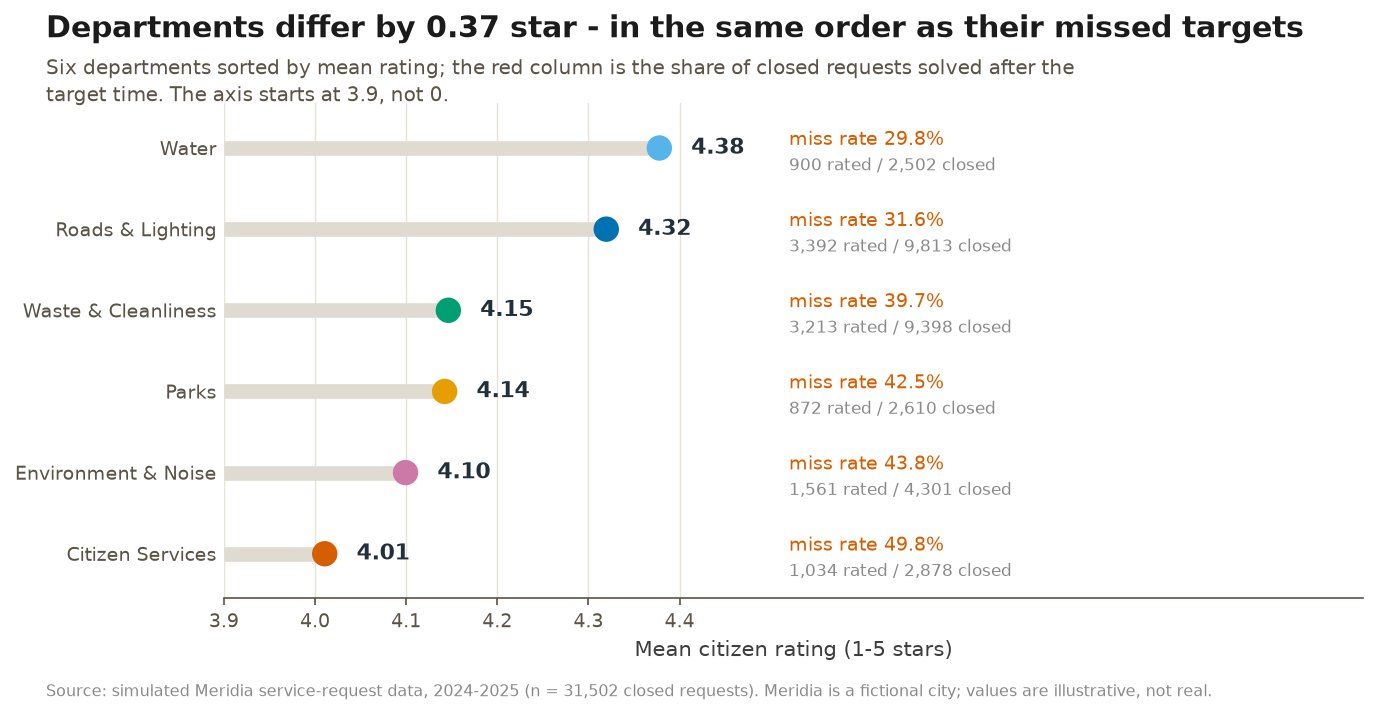

In [11]:
dep = C.groupby("department").agg(n=("request_id", "size"), miss=("missed", "mean"))
dep = dep.join(rated.groupby("department")["citizen_rating"]
               .agg(["size", "mean"]).rename(columns={"size": "n_rated", "mean": "rating"}))
dep = dep.sort_values("rating")
y = np.arange(len(dep))
display(dep.round(3))

dep_by_pri = rated.pivot_table(index="department", columns="priority",
                               values="citizen_rating", aggfunc="mean"
                               ).reindex(columns=["high", "medium", "low"]).round(3)
print("department mean rating inside each priority level:")
display(dep_by_pri)
print("span (best - worst department) inside each level:")
print((dep_by_pri.max() - dep_by_pri.min()).round(3).to_string())

fig, ax = plt.subplots(figsize=(9.8, 4.4))
ax.hlines(y, 3.90, dep["rating"], color="#E0DBD1", lw=7, zorder=1)
ax.scatter(dep["rating"], y, s=125, color=[DEPT_COLOR[d] for d in dep.index], zorder=3)
for yy, (name, row) in zip(y, dep.iterrows()):
    ax.text(row["rating"] + 0.035, yy, f"{row['rating']:.2f}", va="center",
            fontsize=10.5, fontweight="bold", color=INK)
    ax.text(4.52, yy + 0.10, f"miss rate {row['miss']:.1%}", va="center",
            fontsize=9.2, color=MISS)
    ax.text(4.52, yy - 0.22, f"{int(row['n_rated']):,} rated / {int(row['n']):,} closed",
            va="center", fontsize=8.2, color="#8a8a8a")
ax.set_yticks(y, dep.index)
ax.set_xlim(3.90, 5.15); ax.set_xticks([3.9, 4.0, 4.1, 4.2, 4.3, 4.4])
ax.set_ylim(-0.55, len(dep) - 0.45)
ax.set_xlabel("Mean citizen rating (1-5 stars)")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

fig_header(fig, "Departments differ by 0.37 star - in the same order as their missed targets",
           "Six departments sorted by mean rating; the red column is the share of closed requests solved "
           "after the target time. The axis starts at 3.9, not 0.", top=0.86)
src_note(fig, len(C))
save_fig(fig, "S3_department_rating.png", len(C))


Department means run from 4.38 (Water) to 4.01 (Citizen Services), a 0.37-star span, one eighth of SQ1 and in almost the same order as missed targets (29.8% vs 49.8%). The axis starts at 3.9, not 0, to make the small difference readable; departments also receive different kinds of work.

saved S4_category_miss_rate.png  1432x916 px  106 kB


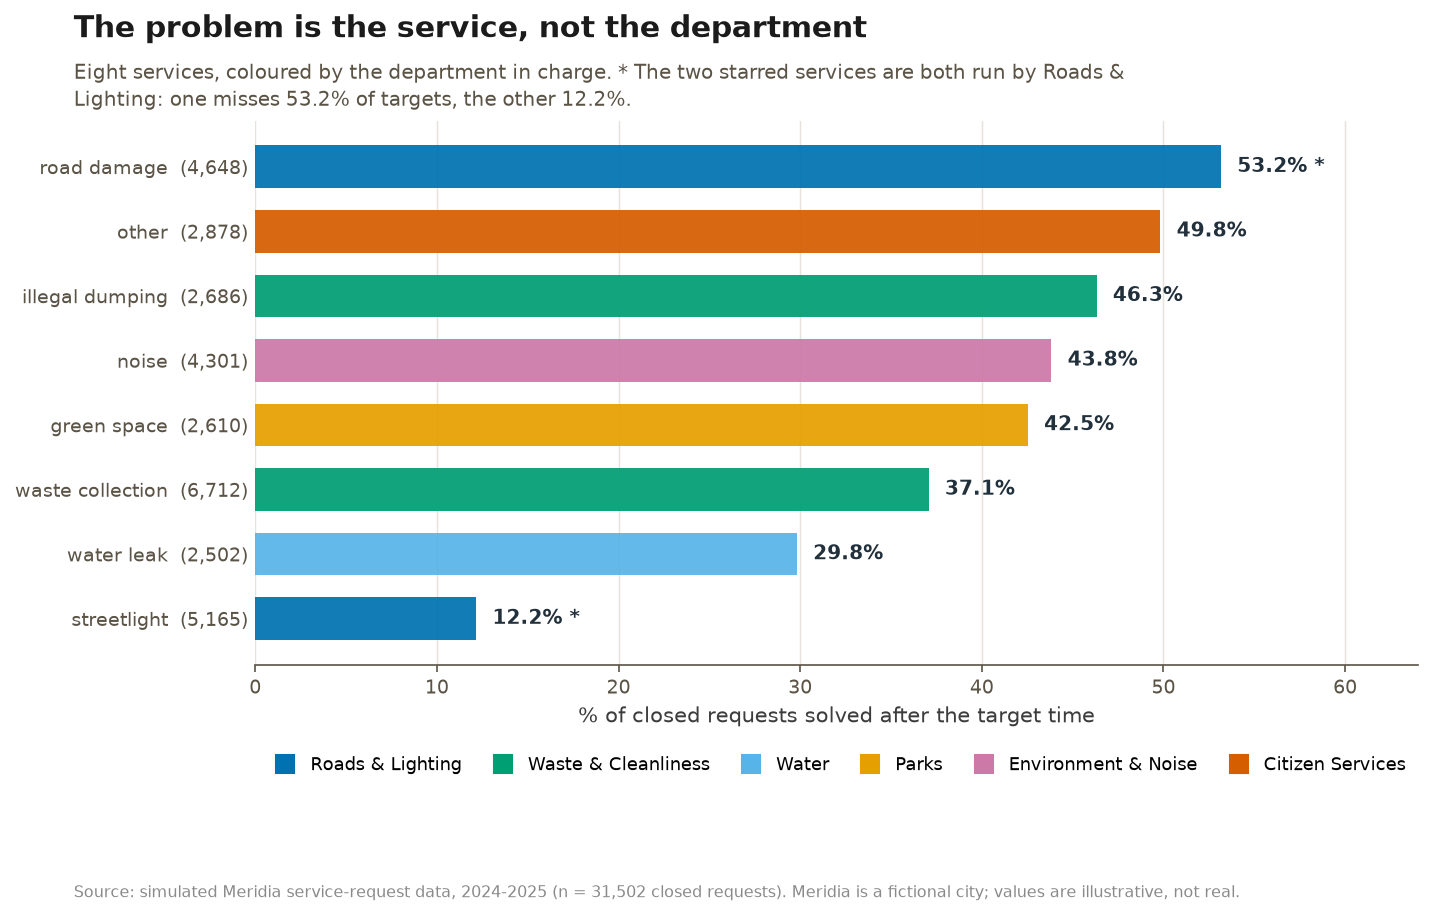

In [12]:
cat = C.groupby("category").agg(n=("request_id", "size"), miss=("missed", "mean"),
                                dept=("department", "first")).sort_values("miss")
y = np.arange(len(cat))
flagged = {"road_damage", "streetlight"}

fig, ax = plt.subplots(figsize=(10.0, 4.9))
ax.barh(y, cat["miss"] * 100, color=[DEPT_COLOR[d] for d in cat["dept"]], height=0.66, alpha=0.93)
for yy, (name, row) in zip(y, cat.iterrows()):
    ax.text(row["miss"] * 100 + 0.9, yy, f"{row['miss']:.1%}" + (" *" if name in flagged else ""),
            va="center", fontsize=9.4, fontweight="bold", color=INK)
ax.set_yticks(y, [f"{c.replace('_', ' ')}  ({int(n):,})" for c, n in zip(cat.index, cat["n"])])
ax.set_xlim(0, 64)
ax.set_xlabel("% of closed requests solved after the target time")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=9.2)

handles = [plt.Line2D([], [], marker="s", ls="", ms=8.5, color=c, label=d)
           for d, c in DEPT_COLOR.items()]
ax.legend(handles=handles, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.155),
          handletextpad=0.4, columnspacing=1.3, borderaxespad=0.0, fontsize=8.6)

fig_header(fig, "The problem is the service, not the department",
           "Eight services, coloured by the department in charge. * The two starred services are both "
           "run by Roads & Lighting: one misses 53.2% of targets, the other 12.2%.", top=0.85)
src_note(fig, len(C), dy=-0.19)
save_fig(fig, "S4_category_miss_rate.png", len(C))


Miss rates run from 12.2% (streetlights) to 53.2% (road damage), 41 points, twice the 20-point department span. Both extremes belong to Roads & Lighting. Inside Waste & Cleanliness the two services differ by 9 points (37.1% vs 46.3%). Each service belongs to one department, so department and service cannot be fully separated; `other` is a catch-all run by Citizen Services.

In [26]:
svc = (C.groupby("category")
         .agg(requests=("request_id", "size"), miss=("missed", "mean"),
              median_h=("hours", "median"), dept=("department", "first"))
         .join(rated.groupby("category")["citizen_rating"].mean().rename("rating"))
         .reset_index())

def bubble(x, xlabel, log):
    f = px.scatter(svc, x=x, y="rating", size="requests", color="dept", size_max=48,
                   color_discrete_map=DEPT_COLOR, hover_name="category", log_x=log,
                   hover_data={"requests": ":,", "miss": ":.1%", "rating": ":.2f",
                               "median_h": ":.0f", "dept": False},
                   labels={x: xlabel, "rating": "mean rating (1-5)", "dept": "department"})
    return f

fig_miss = bubble("miss", "share of targets missed", False)
fig_time = bubble("median_h", "median hours to close (log scale)", True)

fig = go.Figure(data=list(fig_miss.data) + list(fig_time.data))
n = len(fig_miss.data)
for tr in fig.data[n:]:
    tr.visible = False
    tr.showlegend = False

fig.update_layout(
    title=dict(text="<b>Eight services: the ones that miss more are rated lower</b><br>"
                    "<sup>Bubble size = requests. Hover any service for its numbers; "
                    "switch the x-axis to see that volume or speed does not explain the rating</sup>",
               x=0.01, xanchor="left"),
    xaxis=dict(title="share of targets missed", tickformat=".0%", rangemode="tozero"),
    yaxis=dict(title="Mean citizen rating (1-5 stars)", range=[3.8, 4.8]),
    legend=dict(title="department", x=1.02, y=1, bgcolor="rgba(255,255,255,0.75)"),
    margin=dict(l=10, r=10, t=95, b=10), height=520,
    updatemenus=[dict(
        type="buttons", direction="right", x=1.1, y=1.15, xanchor="right", yanchor="top",
        buttons=[
            dict(label="Missed targets", method="update",
                 args=[{"visible": [True] * n + [False] * n},
                       {"xaxis": {"title": "share of targets missed", "type": "linear",
                                  "tickformat": ".0%", "rangemode": "tozero"}}]),
            dict(label="Median hours", method="update",
                 args=[{"visible": [False] * n + [True] * n},
                       {"xaxis": {"title": "median hours to close", "type": "log",
                                  "tickformat": "", "rangemode": "normal"}}])])])

out = INT_DIR / "I2_sq2_service_bubble.html"
fig.write_html(out, include_plotlyjs=True, full_html=True)
print(f"{out.name}: {out.stat().st_size/1024/1024:.1f} MB (self-contained, opens offline)")
fig.show()


I2_sq2_service_bubble.html: 4.6 MB (self-contained, opens offline)


I2 puts all eight services on one plane (colour = department, size = volume) and switches the x-axis between missed targets and median hours. The cloud slopes with missed targets, not with volume or speed.

### 4.3 SQ3: does the priority flag predict the rating?

Compare mean ratings across the three priority levels, then check high minus low inside each service. A real effect should keep the same sign everywhere.

,n,median_h,miss,n_rated,rating,low
priority,,,,,,
high,5254,13.908,0.397,1864,4.189,0.067
medium,14404,64.942,0.377,5008,4.209,0.076
low,11844,134.925,0.379,4100,4.191,0.077


high - low rating inside each service:
category
illegal_dumping    -0.23
streetlight        -0.11
green_space        -0.05
road_damage        -0.02
noise               0.01
water_leak          0.03
other               0.04
waste_collection    0.05
services where high scores worse: 4 | better: 4
saved S5_priority_speed_vs_rating.png  1368x706 px  79 kB


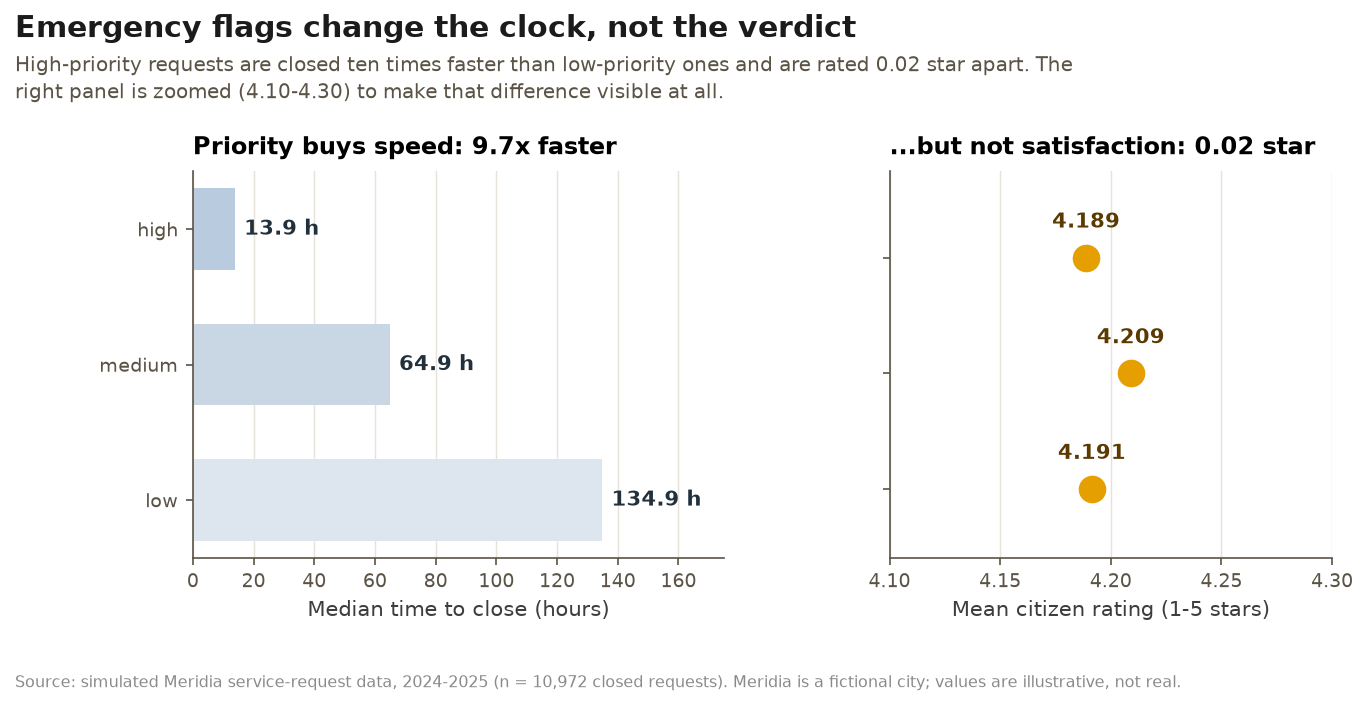

In [14]:
order = ["high", "medium", "low"]
pri = C.groupby("priority").agg(n=("request_id", "size"), median_h=("hours", "median"),
                                miss=("missed", "mean")).reindex(order)
pri = pri.join(rated.groupby("priority")["citizen_rating"]
               .agg(["size", "mean"]).rename(columns={"size": "n_rated", "mean": "rating"}))
pri["low"] = rated.groupby("priority")["citizen_rating"].apply(lambda s: s.le(2).mean())
display(pri.round(3))

hi_lo = rated.pivot_table(index="category", columns="priority",
                          values="citizen_rating", aggfunc="mean")
diffs = (hi_lo["high"] - hi_lo["low"]).dropna().sort_values()
print("high - low rating inside each service:")
print(diffs.round(2).to_string())
print(f"services where high scores worse: {(diffs < 0).sum()} | better: {(diffs > 0).sum()}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.8, 4.1),
                               gridspec_kw={"wspace": 0.34, "width_ratios": [1.2, 1]})
y = np.arange(len(order))[::-1]

ax1.barh(y, pri["median_h"].values, color=["#B9CBDE", "#C9D6E4", "#DDE6EF"], height=0.6)
for yy, v in zip(y, pri["median_h"].values):
    ax1.text(v + 3, yy, f"{v:.1f} h", va="center", fontsize=10, fontweight="bold", color=INK)
ax1.set_yticks(y, order)
ax1.set_xlim(0, 175)
ax1.set_xlabel("Median time to close (hours)")
ax1.set_title("Priority buys speed: 9.7x faster")
ax1.grid(axis="y", visible=False)

ax2.set_xlim(4.10, 4.30)
ax2.scatter(pri["rating"].values, y, s=150, color=ACCENT, zorder=3)
for yy, v in zip(y, pri["rating"].values):
    ax2.text(v, yy + 0.26, f"{v:.3f}", ha="center", fontsize=10, fontweight="bold", color="#5a3a00")
ax2.set_yticks(y, [""] * 3)
ax2.set_ylim(-0.6, 2.75)
ax2.set_xlabel("Mean citizen rating (1-5 stars)")
ax2.set_title("...but not satisfaction: 0.02 star")
ax2.grid(axis="y", visible=False)

fig_header(fig, "Emergency flags change the clock, not the verdict",
           "High-priority requests are closed ten times faster than low-priority ones and are rated 0.02 star "
           "apart. The right panel is zoomed (4.10-4.30) to make that difference visible at all.", top=0.74)
src_note(fig, len(rated), dy=-0.08)
save_fig(fig, "S5_priority_speed_vs_rating.png", len(rated))


Mean ratings are 4.189 / 4.209 / 4.191 for high / medium / low (0.02-star span), while median time is 13.9 / 64.9 / 134.9 h and miss rates are 39.7 / 37.7 / 37.9%. Inside the eight services, high minus low runs from -0.23 to +0.05 with four negative and four positive, so the average difference is not an effect.

In [15]:
grp = (rated.groupby(["category", "priority"])
            .agg(n=("request_id", "size"), rating=("citizen_rating", "mean"),
                 median_h=("hours", "median")).reset_index())

fig = px.scatter(grp, x="median_h", y="rating", color="priority", size="n", size_max=30,
                 category_orders={"priority": ["high", "medium", "low"]},
                 color_discrete_map={"high": MISS, "medium": ACCENT, "low": KEPT},
                 hover_name="category", log_x=True,
                 hover_data={"n": ":,", "median_h": ":.0f", "rating": ".3f"},
                 labels={"median_h": "median hours to close (log scale)",
                         "rating": "mean rating (1-5)", "n": "rated requests",
                         "priority": "priority"})
fig.update_yaxes(range=[3.75, 4.65])
fig.update_layout(
    title=dict(text="<b>Speed and satisfaction do not move together</b><br>"
                    "<sup>24 points = 8 services x 3 priorities; size = rated requests. A left-right move "
                    "changes speed, an up-down move changes the rating. The y axis is zoomed (3.75-4.65)</sup>",
               x=0.01, xanchor="left"),
    legend=dict(title="priority", x=1.02, y=1),
    margin=dict(l=10, r=10, t=95, b=10), height=520)

out = INT_DIR / "I3_sq3_priority_cloud.html"
fig.write_html(out, include_plotlyjs=True, full_html=True)
print(f"{out.name}: {out.stat().st_size/1024/1024:.1f} MB (self-contained, opens offline)")
fig.show()


I3_sq3_priority_cloud.html: 4.6 MB (self-contained, opens offline)


I3 opens the three averages into 24 service x priority points, with median speed on x and rating on y. Moving right does not move the points up.

### 4.4 SQ4: does the reporting channel change the rating?

Compare mean ratings by channel, then app vs phone inside each service. A channel effect should keep the same sign across services.

,n,miss,median_h,n_rated,rating,low
channel,,,,,,
mobile_app,14832,0.353,70.475,5160,4.255,0.067
in_person,2028,0.399,84.242,713,4.175,0.073
web,5088,0.407,73.767,1766,4.152,0.083
phone,9554,0.407,71.800,3333,4.142,0.083


channel,mobile_app,phone,d
category,,,
illegal_dumping,3.961,4.111,-0.150
road_damage,3.903,3.933,-0.030
noise,4.091,4.118,-0.027
green_space,4.130,4.147,-0.017
waste_collection,4.210,4.182,0.028
streetlight,4.693,4.603,0.091
water_leak,4.432,4.331,0.101
other,4.071,3.930,0.141


saved S6_channel_dumbbell.png  1374x761 px  84 kB


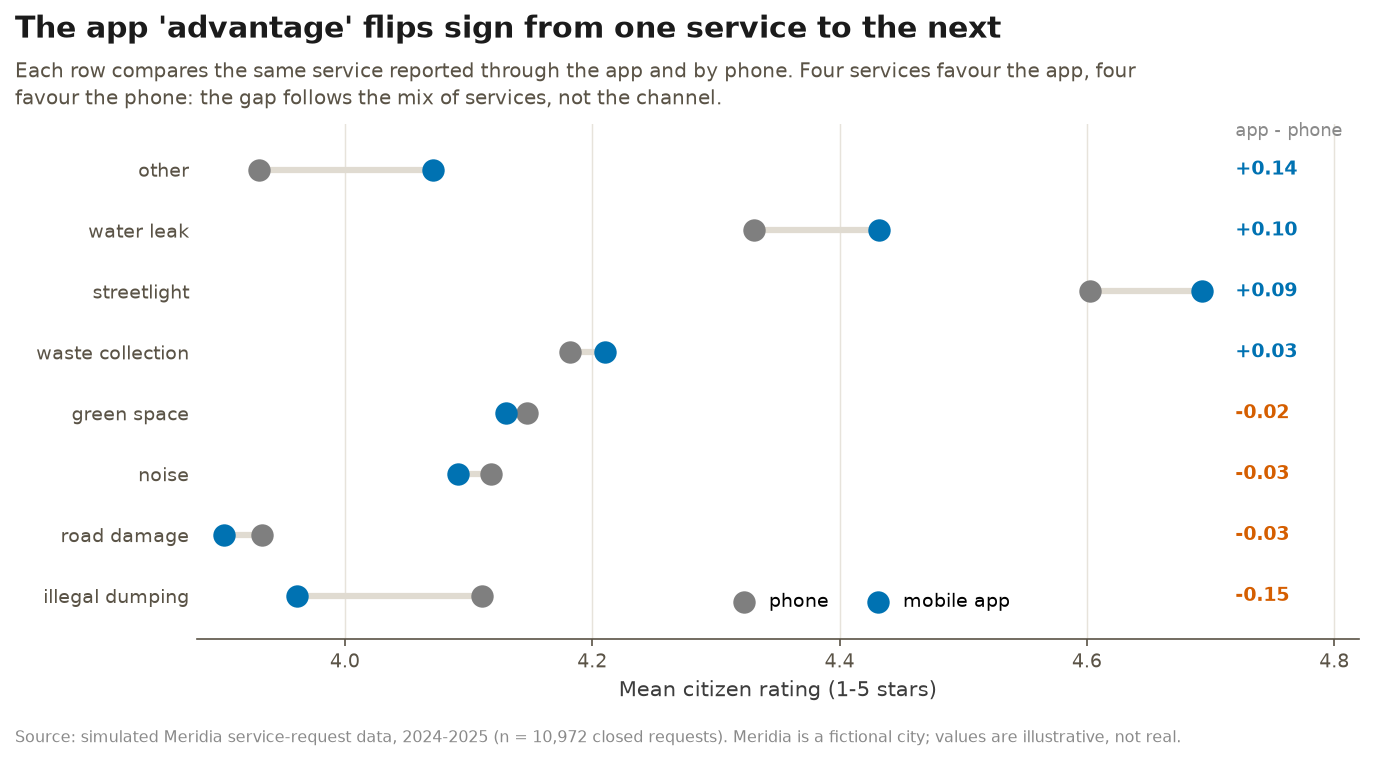

In [16]:
ch = C.groupby("channel").agg(n=("request_id", "size"), miss=("missed", "mean"),
                              median_h=("hours", "median"))
ch = ch.join(rated.groupby("channel")["citizen_rating"]
             .agg(["size", "mean"]).rename(columns={"size": "n_rated", "mean": "rating"}))
ch["low"] = rated.groupby("channel")["citizen_rating"].apply(lambda s: s.le(2).mean())
display(ch.sort_values("rating", ascending=False).round(3))

piv = rated.pivot_table(index="category", columns="channel",
                        values="citizen_rating", aggfunc="mean")[["mobile_app", "phone"]].dropna()
piv["d"] = piv["mobile_app"] - piv["phone"]
piv = piv.sort_values("d")
display(piv.round(3))
y = np.arange(len(piv))

fig, ax = plt.subplots(figsize=(10.0, 4.7))
ax.hlines(y, piv["phone"], piv["mobile_app"], color="#E0DBD1", lw=3.0, zorder=1)
ax.scatter(piv["phone"], y, s=95, color=NEUTRAL, zorder=3, label="phone")
ax.scatter(piv["mobile_app"], y, s=95, color=KEPT, zorder=3, label="mobile app")
for yy, d in zip(y, piv["d"]):
    ax.text(4.72, yy, f"{d:+.2f}", va="center", ha="left", fontsize=9.2,
            color=(MISS if d < 0 else KEPT), fontweight="bold")
ax.set_yticks(y, [c.replace("_", " ") for c in piv.index])
ax.set_xlim(3.88, 4.82); ax.set_ylim(-0.7, len(piv) - 0.25)
ax.set_xlabel("Mean citizen rating (1-5 stars)")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(4.72, len(piv) - 0.45, "app - phone", fontsize=8.6, color="#8a8a8a")
ax.legend(loc="lower left", bbox_to_anchor=(0.44, 0.02), ncol=2,
          handletextpad=0.35, columnspacing=1.6)

fig_header(fig, "The app 'advantage' flips sign from one service to the next",
           "Each row compares the same service reported through the app and by phone. Four services favour "
           "the app, four favour the phone: the gap follows the mix of services, not the channel.", top=0.84)
src_note(fig, len(rated))
save_fig(fig, "S6_channel_dumbbell.png", len(rated))


Channels are close: 4.26 (app), 4.18 (in person), 4.15 (web), 4.14 (phone), a 0.11-star span. App minus phone inside services runs from -0.15 to +0.14, four negative and four positive. The app is the largest channel (5,160 rated requests) and its users may be self-selected; with the sign flipping, a channel intervention is not supported.

In [17]:
ch2 = (rated[rated["channel"].isin(["mobile_app", "phone"])]
       .groupby(["category", "channel"])
       .agg(rating=("citizen_rating", "mean"), n=("request_id", "size")).reset_index())

fig = px.bar(ch2, x="rating", y="category", color="channel", barmode="group", orientation="h",
             color_discrete_map={"mobile_app": KEPT, "phone": NEUTRAL},
             hover_data={"n": ":,", "rating": ":.3f", "channel": False},
             labels={"rating": "mean rating (1-5)", "category": "", "channel": "channel"})
fig.update_xaxes(range=[3.85, 4.75])
fig.update_layout(
    title=dict(text="<b>App vs phone, service by service</b><br>"
                    "<sup>Bars are mean ratings on rated requests. Click a channel in the legend to isolate "
                    "it; hover for the number of ratings behind each bar. The x axis starts at 3.85, not 0</sup>",
               x=0.01, xanchor="left"),
    legend=dict(title="", x=1.02, y=1),
    margin=dict(l=10, r=10, t=95, b=10), height=520)

out = INT_DIR / "I4_sq4_channel_bars.html"
fig.write_html(out, include_plotlyjs=True, full_html=True)
print(f"{out.name}: {out.stat().st_size/1024/1024:.1f} MB (self-contained, opens offline)")
fig.show()


I4_sq4_channel_bars.html: 4.6 MB (self-contained, opens offline)


I4 shows the n behind every bar on hover and isolates a channel with one click, so the four "app ahead" services can be checked against their size.

### 4.5 Context: time and place

Two static figures ask whether missed targets are getting worse and whether they cluster in particular districts; I5 switches the district map between three metrics.

saved S7_monthly_volume_and_miss.png  1347x867 px  111 kB


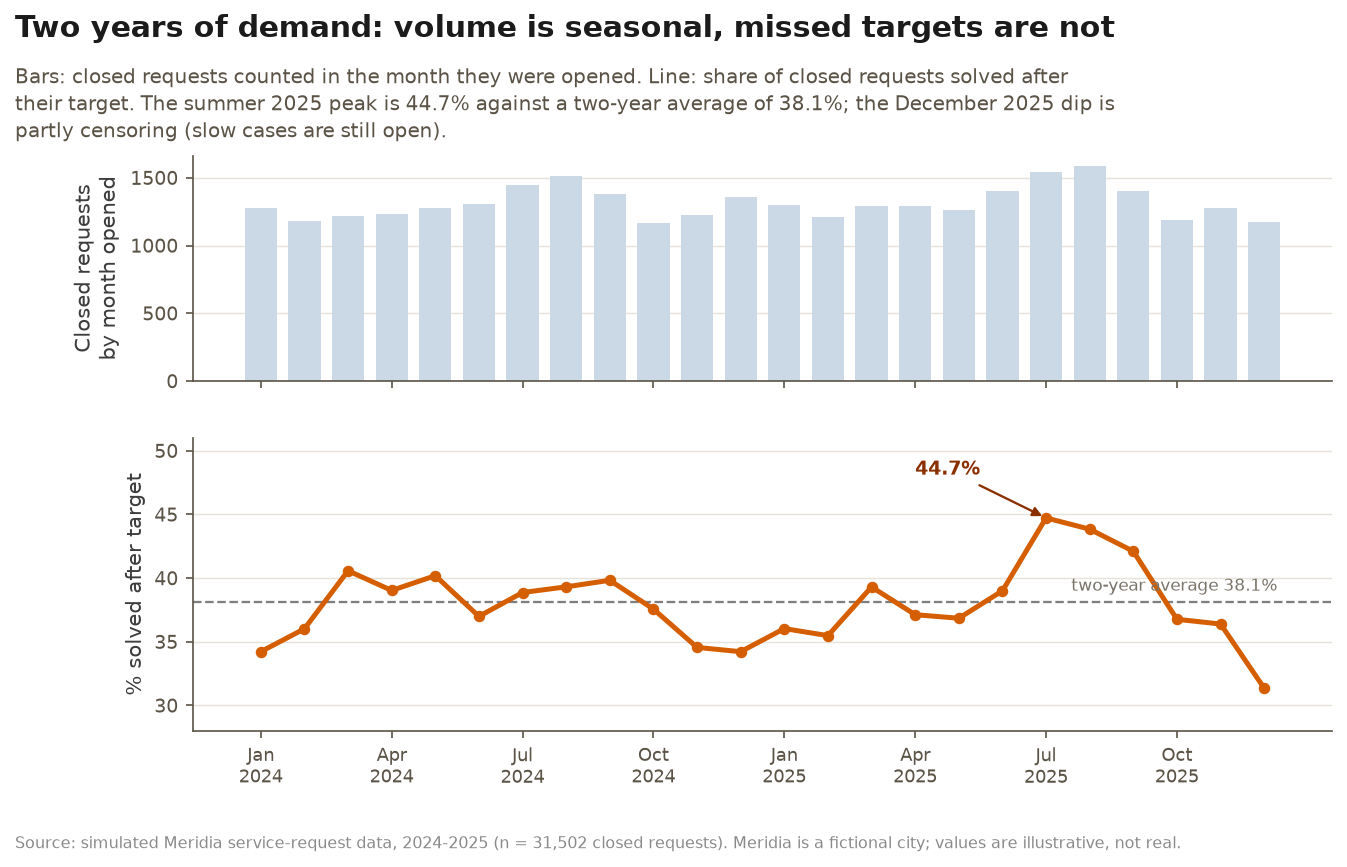

In [18]:
# Two panels rather than dual y axes.
monthly = C.set_index("created_at").resample("MS").agg(n=("request_id", "size"),
                                                       miss=("missed", "mean"))
x = np.arange(len(monthly))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.8, 5.4), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1.3], "hspace": 0.22})

ax1.bar(x, monthly["n"], color="#CBD8E6", width=0.74)
ax1.set_ylabel("Closed requests\nby month opened")
ax1.grid(axis="x", visible=False)

ax2.plot(x, monthly["miss"] * 100, "-o", color=MISS, lw=2.4, ms=4.5, zorder=3)
ax2.axhline(C["missed"].mean() * 100, color=NEUTRAL, ls="--", lw=1.1)
ax2.text(len(monthly) - 0.7, C["missed"].mean() * 100 + 0.9,
         f"two-year average {C['missed'].mean():.1%}", ha="right", fontsize=8.4, color="#7a7469")
peak = int(np.argmax(monthly["miss"].values))
ax2.annotate(f"{monthly['miss'].max():.1%}", xy=(peak, monthly["miss"].max() * 100),
             xytext=(peak - 3.0, monthly["miss"].max() * 100 + 3.4), fontsize=9.2,
             color="#8a2f00", fontweight="bold",
             arrowprops=dict(arrowstyle="-|>", color="#8a2f00", lw=1.1))
ax2.set_ylim(28, 51)
ax2.set_ylabel("% solved after target")
ax2.set_xticks(x[::3], [d.strftime("%b\n%Y") for d in monthly.index[::3]], fontsize=8.6)
ax2.grid(axis="x", visible=False)

fig_header(fig, "Two years of demand: volume is seasonal, missed targets are not",
           "Bars: closed requests counted in the month they were opened. Line: share of closed requests solved after their target. "
           "The summer 2025 peak is 44.7% against a two-year average of 38.1%; the December 2025 dip is "
           "partly censoring (slow cases are still open).", top=0.82)
src_note(fig, len(C))
save_fig(fig, "S7_monthly_volume_and_miss.png", len(C))


saved S8_request_rate_map.png  1196x867 px  123 kB


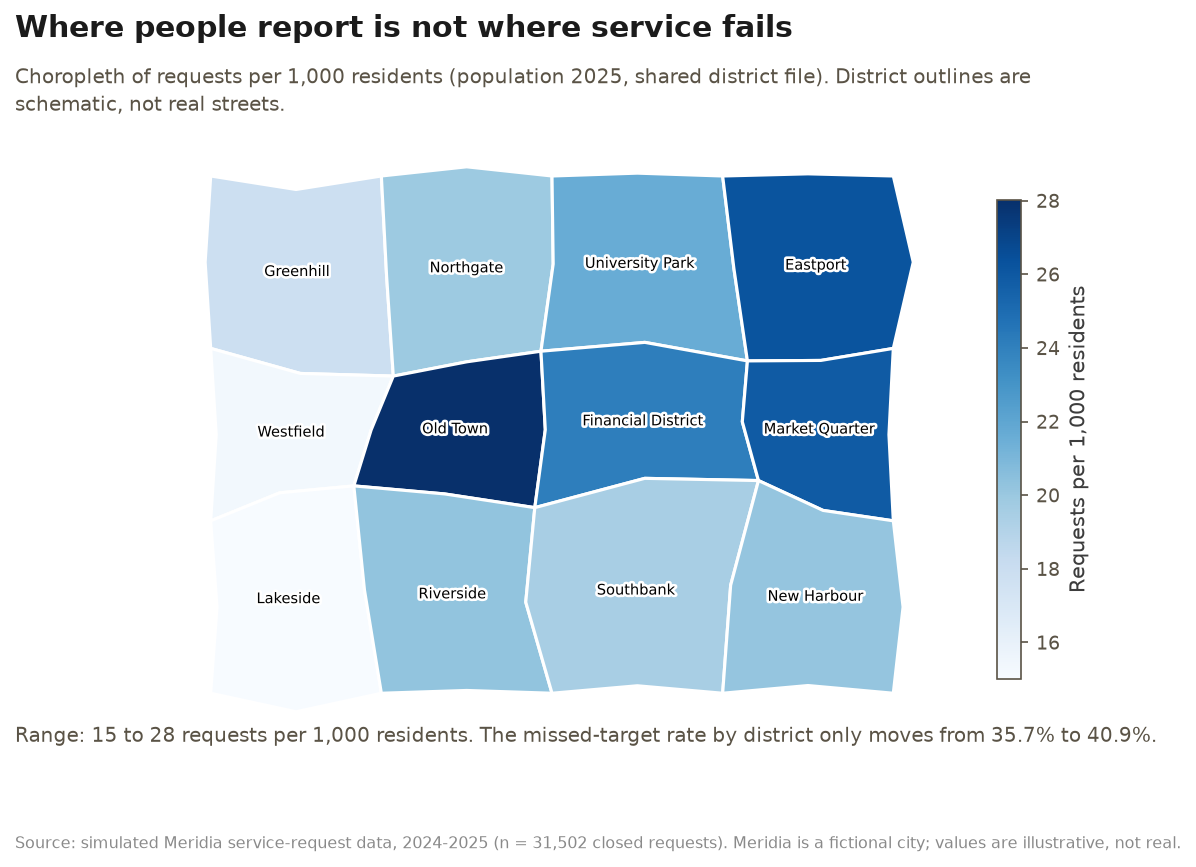

,miss,n,per_1000
district_id,,,
D06,0.394,4471,28.031
D04,0.375,2220,26.241
D08,0.403,3876,25.892
D07,0.360,1449,24.150
D03,0.369,2624,21.650
D10,0.359,2646,20.276
D12,0.371,1834,20.154
D02,0.375,4190,19.914
D11,0.393,3422,19.499


In [19]:
# No real basemap: Meridia is fictional.
import sys
sys.path.insert(0, str(DATA_DIR))
from meridia_map_helpers import load_districts, plot_district_map

gj = load_districts(str(DATA_DIR / "districts.geojson"))
d = C.merge(districts, on="district_id", how="left")
dtab = d.groupby("district_id").agg(miss=("missed", "mean"), n=("request_id", "size"))
dtab["per_1000"] = dtab["n"] / (districts.set_index("district_id").loc[dtab.index, "population_2025"] / 1000)

fig, ax = plt.subplots(figsize=(8.4, 5.4))
fig.subplots_adjust(bottom=0.10)
plot_district_map(gj, values=dtab["per_1000"], ax=ax, cmap="Blues",
                  title="", legend_label="Requests per 1,000 residents")
fig.text(0.004, 0.115,
         f"Range: {dtab['per_1000'].min():.0f} to {dtab['per_1000'].max():.0f} requests per 1,000 residents. "
         f"The missed-target rate by district only moves from {dtab['miss'].min():.1%} to {dtab['miss'].max():.1%}.",
         fontsize=9.4, color=MUTED, ha="left", va="top")

fig_header(fig, "Where people report is not where service fails",
           "Choropleth of requests per 1,000 residents (population 2025, shared district file). "
           "District outlines are schematic, not real streets.", top=0.84)
src_note(fig, len(C))
save_fig(fig, "S8_request_rate_map.png", len(C))
display(dtab.sort_values("per_1000", ascending=False).round(3))


Demand peaks in summer (July 2025 has the highest miss rate, 44.7%), but the two-year average is 38.1% with no trend. Districts sit between 35.7% and 40.9% while requests per 1,000 residents range from 15 to 28: where people report is not where service fails.

In [28]:
# Hide the world map: no real coastline may appear.
import json

with open(DATA_DIR / "districts.geojson", encoding="utf-8") as f:
    geo = json.load(f)

dis = districts.set_index("district_id")
dd = (C.merge(districts, on="district_id")
        .groupby("district_id")
        .agg(requests=("request_id", "size"), miss=("missed", "mean")).reindex(dis.index))
dd["per_1000"] = dd["requests"] / (dis["population_2025"] / 1000)
dd["name"] = dis["district_name"]

# Metrics live in customdata, so switching layers needs no rebuild.
custom = [[str(n), int(r), round(float(p), 1), round(float(m), 3), int(pop)]
          for n, r, p, m, pop in zip(dd["name"], dd["requests"], dd["per_1000"],
                                     dd["miss"], dis["population_2025"])]

def map_layer(z, bar_title, colorscale):
    """One layer per metric; buttons toggle visibility."""
    z = [float(v) for v in z]
    return go.Choropleth(
        geojson=geo, locations=list(dd.index), z=z,
        featureidkey="properties.district_id",
        colorscale=colorscale, zmin=min(z), zmax=max(z),
        marker_line_width=1.2, marker_line_color="white",
        customdata=custom, showlegend=False,
        hovertemplate=("<b>%{customdata[0]}</b><br>"
                       "requests: %{customdata[1]:,}<br>"
                       "per 1,000 residents: %{customdata[2]:.1f}<br>"
                       "missed target: %{customdata[3]:.1%}<br>"
                       "population: %{customdata[4]:,}<extra></extra>"),
        colorbar=dict(title=dict(text=bar_title), thickness=14, len=0.72))

fig = go.Figure(data=[
    map_layer(dd["per_1000"], "requests<br>per 1,000", "Blues"),
    map_layer(dd["requests"], "requests", "Teal"),
    map_layer(dd["miss"], "missed<br>target", "OrRd"),
])
fig.data[1].visible = False
fig.data[2].visible = False

fig.update_geos(visible=False, fitbounds="locations")
fig.update_layout(
    title=dict(text="<b>Requests per 1,000 residents, by district</b><br>"
                    "<sup>Population-normalised rate, the metric the brief asks for. Switch the metric with "
                    "the buttons; hover for the raw numbers</sup>",
               x=0.01, xanchor="left"),
    margin=dict(l=0, r=0, t=95, b=0), height=560,
    updatemenus=[dict(
        type="buttons", direction="right", x=1.08, y=1.13, xanchor="right", yanchor="top",
        buttons=[
            dict(label="Per 1,000 residents", method="update",
                 args=[{"visible": [True, False, False]}]),
            dict(label="Total requests", method="update",
                 args=[{"visible": [False, True, False]}]),
            dict(label="Missed-target rate", method="update",
                 args=[{"visible": [False, False, True]}])])])

out = INT_DIR / "I5_request_rate_map.html"
fig.write_html(out, include_plotlyjs=True, full_html=True)
print(f"{out.name}: {out.stat().st_size/1024/1024:.1f} MB (self-contained, opens offline)")
fig.show()


I5_request_rate_map.html: 4.6 MB (self-contained, opens offline)


I5 defaults to requests per 1,000 residents (a reporting rate rather than a population count) and switches to total requests and miss rate. The district ranking changes with the metric, and none of the three rankings is dramatic.

## 5. Interactive views

| File | Where | What it adds |
|---|---|---|
| `I1_sq1_switchable_scatter.html` | 4.1 | switch x between absolute hours and hours relative to target |
| `I2_sq2_service_bubble.html` | 4.2 | all eight services, hover for volume/rating, switch x between miss rate and median hours |
| `I3_sq3_priority_cloud.html` | 4.3 | 24 service x priority points instead of three averages |
| `I4_sq4_channel_bars.html` | 4.4 | isolate a channel, read the n behind each bar |
| `I5_request_rate_map.html` | 4.5 | switch the district map between three metrics |

All five embed plotly.js and open offline. No animation, 3-D or real basemap: Meridia is fictional, so a coastline would be invented. Each view answers one question the static charts cannot.

## 6. BI dashboard tables

Eleven UTF-8 CSVs go to `bi_export/`. The fact table has one row per closed request, so every measure can be recomputed from it; five dimension tables hold labels and slicers, four `bi_sq*` tables hold the per-question aggregates, and `bi_kpi_overall.csv` holds the fixed KPI cards. The fact table carries `missed` (0/1), `band` (actual / target), `channel_type` and `month`, so slicing by them needs no join.

| Measure | Definition | Formula |
|---|---|---|
| On-time rate | share closed within target | `DIVIDE(COUNTROWS(FILTER(fact, fact[missed] = FALSE)), COUNTROWS(fact))` |
| Missed-target rate | complement | `DIVIDE(CALCULATE(COUNTROWS(fact), fact[missed] = TRUE), COUNTROWS(fact))` |
| Median hours | typical wait | `MEDIAN(fact[hours])` |
| Mean rating | rated requests only | `AVERAGEX(FILTER(fact, fact[citizen_rating] <> BLANK()), fact[citizen_rating])` |
| Response rate | share rated | `DIVIDE(CALCULATE(COUNTROWS(fact), fact[citizen_rating] <> BLANK()), COUNTROWS(fact))` |
| 1-2 star share | low-rating tail | `DIVIDE(CALCULATE(COUNTROWS(fact), fact[citizen_rating] <= 2), CALCULATE(COUNTROWS(fact), fact[citizen_rating] <> BLANK()))` |

All measures use the 31,502 closed rows. Table list and build notes are in `bi/dashboard_notes.md`.

In [21]:
import numpy as np

BI_DIR = ROOT / "bi_export"
BI_DIR.mkdir(parents=True, exist_ok=True)
for old in ["bi_sq2_category.csv", "bi_sq2_department.csv"]:
    p = BI_DIR / old
    if p.exists():
        p.unlink()
        print("removed old file:", old)

CHANNEL_ORDER = ["mobile_app", "web", "phone", "in_person"]
CHANNEL_TYPE  = {"mobile_app": "digital", "web": "digital",
                 "phone": "traditional", "in_person": "traditional"}
assert set(CHANNEL_TYPE) == set(CHANNEL_ORDER), "channel registry changed"
assert set(CHANNEL_TYPE.values()) == {"digital", "traditional"}

PRIO_ORDER = ["high", "medium", "low"]
PRIO_LABEL = {"high": "High", "medium": "Medium", "low": "Low"}
DEPT_ORDER = list(DEPT_COLOR)     

BANDS  = [0, 0.5, 1.0, 1.5, 2.0, 3.0, np.inf]
BAND_LABELS = ["< 0.5x", "0.5-1x", "1-1.5x", "1.5-2x", "2-3x", "> 3x"]
band_all = pd.cut(C["ratio"], bins=BANDS, labels=BAND_LABELS, right=False)

fact = pd.DataFrame({
    "request_id":     C["request_id"].astype(str),
    "created_at":     C["created_at"],
    "closed_at":      C["closed_at"],
    "district_id":    C["district_id"].astype(str),
    "channel":        C["channel"].astype(str),
    "channel_type":   C["channel"].map(CHANNEL_TYPE).astype(str),
    "cat":            C["category"].astype(str),
    "department":     C["department"].astype(str),
    "priority":       C["priority"].astype(str),
    "status":         C["status"].astype(str),
    "hours":          C["hours"].round(3),
    "target_hours":   C["target_hours"].astype(int),
    "ratio":          C["ratio"].round(3),
    "missed":         C["missed"].astype(int),
    "band":           band_all.astype(str),
    "month":          C["created_at"].dt.to_period("M").astype(str),
    "citizen_rating": C["citizen_rating"].round(3),
})
assert fact["request_id"].is_unique, "fact table must have one row per request"
assert fact["citizen_rating"].notna().sum() == len(rated)
assert int(fact["missed"].sum()) == int(C["missed"].sum())
assert set(fact["band"].unique()) == set(BAND_LABELS)
assert (fact["ratio"] >= 0).all(), "a ratio cannot be negative"

_cat_dept = C.groupby("category")["department"].first()
cat_label_map = {
    "waste_collection": "Waste collection",
    "illegal_dumping":  "Illegal dumping",
    "road_damage":      "Road damage",
    "streetlight":      "Streetlight",
    "water_leak":       "Water leak",
    "green_space":      "Green space",
    "noise":            "Noise",
    "other":            "Other",
}
dim_category = pd.DataFrame({
    "cat":         _cat_dept.index.astype(str),
    "cat_label":   [cat_label_map[c] for c in _cat_dept.index],
    "department":  _cat_dept.values,
}).sort_values(["department", "cat_label"]).reset_index(drop=True)

dim_department = pd.DataFrame({"department": list(DEPT_ORDER)})
dim_department["department_label"] = dim_department["department"]

dim_district = districts[["district_id", "district_name", "profile", "area_km2",
                          "population_2024", "population_2025",
                          "centroid_lat", "centroid_lon"]].copy()

channel_label_map = {
    "mobile_app": "Mobile app",
    "web":        "Website",
    "phone":      "Phone",
    "in_person":  "In person",
}
dim_channel = pd.DataFrame({
    "channel":       CHANNEL_ORDER,
    "channel_label": [channel_label_map[c] for c in CHANNEL_ORDER],
    "channel_type":  [CHANNEL_TYPE[c] for c in CHANNEL_ORDER],
})

dim_priority = pd.DataFrame({
    "priority":       PRIO_ORDER,
    "priority_label": [PRIO_LABEL[p] for p in PRIO_ORDER],
    "sort_order":     [1, 2, 3],
})

band_rated = pd.cut(rated["ratio"], bins=BANDS, labels=BAND_LABELS, right=False)
_br = rated.groupby(band_rated, observed=False)
sq1 = pd.DataFrame({
    "band":         BAND_LABELS,
    "band_order":   range(1, 7),
    "n_rated":      _br.size().astype(int).values,
    "avg_rating":   _br["citizen_rating"].mean().round(3).values,
    "pct_1_2star":  (_br["citizen_rating"].apply(lambda s: s.le(2).mean()) * 100).round(3).values,
})

idx = pd.MultiIndex.from_product([DEPT_ORDER, PRIO_ORDER],
                                 names=["department", "priority"])
_n_req  = C.groupby(["department", "priority"]).size().reindex(idx).rename("n_requests")
_miss   = C.groupby(["department", "priority"])["missed"].mean().reindex(idx).rename("miss_rate")
_n_rated = rated.groupby(["department", "priority"]).size().reindex(idx).rename("n_rated")
_avg    = rated.groupby(["department", "priority"])["citizen_rating"].mean().reindex(idx).rename("avg_rating")
sq2 = (pd.concat([_n_rated, _n_req, _avg, _miss], axis=1)
       .reset_index()
       .assign(n_rated=lambda d: d["n_rated"].astype(int),
               n_requests=lambda d: d["n_requests"].astype(int),
               avg_rating=lambda d: d["avg_rating"].round(3),
               miss_rate=lambda d: d["miss_rate"].round(3)))

_pri  = C.groupby("priority")
_pri_r = rated.groupby("priority")
sq3 = pd.DataFrame({
    "priority":     PRIO_ORDER,
    "n_rated":      _pri_r.size().reindex(PRIO_ORDER).astype(int).values,
    "n_requests":   _pri.size().reindex(PRIO_ORDER).astype(int).values,
    "avg_rating":   _pri_r["citizen_rating"].mean().reindex(PRIO_ORDER).round(3).values,
    "median_hours": _pri["hours"].median().reindex(PRIO_ORDER).round(3).values,
    "miss_rate":    _pri["missed"].mean().reindex(PRIO_ORDER).round(3).values,
})

_ch   = C.groupby("channel")
_ch_r = rated.groupby("channel")
sq4 = pd.DataFrame({
    "channel":     CHANNEL_ORDER,
    "n_rated":     _ch_r.size().reindex(CHANNEL_ORDER).astype(int).values,
    "n_requests":  _ch.size().reindex(CHANNEL_ORDER).astype(int).values,
    "avg_rating":  _ch_r["citizen_rating"].mean().reindex(CHANNEL_ORDER).round(3).values,
    "miss_rate":   _ch["missed"].mean().reindex(CHANNEL_ORDER).round(3).values,
}).sort_values("avg_rating", ascending=False).reset_index(drop=True)

kpi = pd.DataFrame([{
    "n_requests":     int(len(C)),
    "n_rated":        int(len(rated)),
    "response_rate":  round(len(rated) / len(C), 3),
    "on_time_rate":   round(float((~C["missed"]).mean()), 3),
    "miss_rate":      round(float(C["missed"].mean()), 3),
    "median_hours":   round(float(C["hours"].median()), 3),
    "mean_rating":    round(float(rated["citizen_rating"].mean()), 3),
}])

assert len(dim_category) == 8
assert dim_priority["sort_order"].tolist() == [1, 2, 3]
assert set(dim_priority["priority_label"]) == {"High", "Medium", "Low"}
assert len(dim_district) == len(fact["district_id"].unique()) == 12
assert set(fact["cat"])        == set(dim_category["cat"])
assert set(fact["department"]) == set(dim_department["department"])
assert set(fact["district_id"]) == set(dim_district["district_id"])
assert set(fact["channel"])    == set(dim_channel["channel"])
assert set(fact["priority"])   == set(dim_priority["priority"])
for frame in (sq1, sq2, sq3, sq4):
    assert int(frame["n_rated"].sum()) == len(rated), "a summary table does not cover the rated sample"
for frame in (sq2, sq3, sq4):
    assert int(frame["n_requests"].sum()) == len(C), "a summary table does not cover the closed requests"
    assert (frame["n_rated"] <= frame["n_requests"]).all()

BI_COLUMNS = {
    "bi_fact_requests.csv":      ["request_id", "created_at", "closed_at", "district_id", "channel",
                                  "channel_type", "cat", "department", "priority", "status", "hours",
                                  "target_hours", "ratio", "missed", "band", "month", "citizen_rating"],
    "bi_dim_category.csv":       ["cat", "cat_label", "department"],
    "bi_dim_department.csv":     ["department", "department_label"],
    "bi_dim_district.csv":       ["district_id", "district_name", "profile", "area_km2",
                                  "population_2024", "population_2025", "centroid_lat", "centroid_lon"],
    "bi_dim_channel.csv":        ["channel", "channel_label", "channel_type"],
    "bi_dim_priority.csv":       ["priority", "priority_label", "sort_order"],
    "bi_kpi_overall.csv":        ["n_requests", "n_rated", "response_rate", "on_time_rate", "miss_rate",
                                  "median_hours", "mean_rating"],
    "bi_sq1_delay_band.csv":     ["band", "band_order", "n_rated", "avg_rating", "pct_1_2star"],
    "bi_sq2_dept_priority.csv":  ["department", "priority", "n_rated", "n_requests", "avg_rating", "miss_rate"],
    "bi_sq3_priority.csv":       ["priority", "n_rated", "n_requests", "avg_rating", "median_hours", "miss_rate"],
    "bi_sq4_channel.csv":        ["channel", "n_rated", "n_requests", "avg_rating", "miss_rate"],
}
BI_TABLES = [
    ("bi_fact_requests.csv",     fact,          31_502),
    ("bi_dim_category.csv",      dim_category,  8),
    ("bi_dim_department.csv",    dim_department, 6),
    ("bi_dim_district.csv",      dim_district,  12),
    ("bi_dim_channel.csv",       dim_channel,   4),
    ("bi_dim_priority.csv",      dim_priority,  3),
    ("bi_kpi_overall.csv",       kpi,           1),
    ("bi_sq1_delay_band.csv",    sq1,           6),
    ("bi_sq2_dept_priority.csv", sq2,           18),
    ("bi_sq3_priority.csv",      sq3,           3),
    ("bi_sq4_channel.csv",       sq4,           4),
]
assert len(BI_TABLES) == 11, "the dashboard contract is eleven tables"
for name, frame, rows in BI_TABLES:
    assert list(frame.columns) == BI_COLUMNS[name], f"{name}: column contract changed"
    assert len(frame) == rows, f"{name}: {len(frame)} rows, expected {rows}"
    assert frame.columns.is_unique, f"{name}: duplicate column name"

# UTF-8 BOM for Power BI; read back to check row counts.
for name, frame, rows in BI_TABLES:
    path = BI_DIR / name
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    assert path.read_bytes()[:3] == b"\xef\xbb\xbf", f"{name} lost its UTF-8 BOM"
    with path.open("rb") as fh:
        written = sum(1 for _ in fh) - 1
    assert written == rows, f"{name}: wrote {written} rows, expected {rows}"

print(f"Wrote {len(BI_TABLES)} tables to {BI_DIR}/ "
      f"({sum(rows for _, _, rows in BI_TABLES):,} rows in total).")


Wrote 11 tables to c:\Users\xcddn\Desktop\group 15\bi_export/ (31,567 rows in total).


## 7. Sources and tools

- Data: `service_requests.csv` (31,801 rows), `districts.csv`, `districts.geojson`, supplied with the Citizen Service Requests brief (EFREI x WHUT, 2026). Simulated data; Meridia is fictional.
- Map: `meridia_map_helpers.py` draws schematic districts with matplotlib only.
- Colour: Okabe-Ito palette (Okabe & Ito, 2008).
- Tools: Python 3.14, pandas 3.0.6, numpy 2.5.4, matplotlib 3.11.2, plotly 7.1.0.
- The notebook was run top to bottom; every number in the text and every exported file comes from the cells above.

## 8. Findings

| | Answer | Effect |
|---|---|---|
| SQ1 | Yes, and it dominates | 2.86 stars (4.94 -> 2.08); on time 4.71 vs late 3.36 |
| SQ2 | Surface difference; the service drives it | 0.37 star, 0.35-0.38 inside every priority level |
| SQ3 | No | 0.02 star, while median wait differs 9.7x |
| SQ4 | No | 0.11 star, sign flips across services |

Among requests that met their target, fastest and slowest differ by 0.33 stars; when the target is missed, mean rating drops from 4.71 to 3.36 and the 1-2 star share rises from 0.3% to 19.2%. The three "no" answers matter: the city can stop spending on relabelling priority or on a channel strategy for satisfaction, and spend on capacity where promises break. The app is the largest channel (5,160 rated requests), but its advantage does not survive inside services, so digitalisation should be justified by cost or reach.

## 9. Recommendation

1. Use on-time rate instead of average handling time as the department KPI; average time rewards generous targets.
2. Spend the 2026 capacity budget on the services that fail most: road damage misses 53.2% of targets and waste collection carries the largest volume (6,712 requests).
3. Do not allocate by district or build a channel strategy on satisfaction: districts sit between 35.7% and 40.9%, channels differ by 0.11 star with a sign flip.
4. Re-examine the targets. Road damage misses half its targets while streetlights in the same department miss 12.2%; the data show which services fail, not whether the target or the capacity is wrong.

## 10. Limitations

1. Observational data: associations, not causal effects.
2. `target_hours` is a deterministic function of service and priority, so "promise" and "normal wait" cannot be separated; the honest wording is about the wait relative to what is normal for that kind of request.
3. 65% of ratings are missing. The rating rate is flat across channels, districts and outcomes (34-36%), but people who answer may care more. Every rating figure states its n.
4. 236 requests were still open on 31 December 2025; slow December cases are under-represented.
5. Meridia is fictional and the data simulated; no conclusion transfers to a real city.
6. With 31,502 closed requests, a 0.02-star difference is detectable but meaningless, so effects are reported in stars rather than p-values.